# Forest Cover Predictions Using Decision Tree, Random Forest, and SVM Models
Stephanie Gillihan | CSPB 4622 Machine Learning | Fall 2026

---

### Background and Overview
This project compares three supervised machine learning models (Decision Tree, Random Forest, and Support Vector Machine) to predict forest cover type using geographic and environmental data from the UCI Forest Covertype dataset. The main goal is to compare how well the models perform and to understand the strengths and weaknesses of each approach.

The project will begin with exploratory data analysis and basic data preparation. Next, each model will be tested with a small set of hyperparameter values to see how those settings affect performance and to choose reasonable starting values. The models will then be evaluated across repeated stratified random samples so their accuracy, stability, and consistency can be compared. Based on those results, the models will be fine-tuned and tested again. The final section will compare overall performance, training time, interpretability, and the practical tradeoffs between the three models.

#### Dataset Citation
Blackard, J. (1998). Covertype [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C50K5N.

#### Table of Contents
(TO-DO)


---

## Section I: Data Set-up, Exploratory Data Analysis, and Project Design

This section will import all required libraries for the project, process the zipped data, and set up functions for selecting startified random samples. This section will also include Exploratory Data Analysis (EDA). EDA summarizes the data in tabular or graphical form so the user can have a better understanding of features, value ranges, data formats, etc. Finally, this section will layout the project design.

In [16]:
# Import all necessary libraries

# general
import time               # used to time how long each model takes to train and predict
import zipfile            # the raw data is zipped, so this reads it without extracting it first
from pathlib import Path  # builds file paths that work on Windows, Mac, and Linux

# Data/Plotting
import numpy as np                 # numeric arrays
import pandas as pd                # DataFrames for holding data and results
import matplotlib.pyplot as plt    # base plotting library
import seaborn as sns              # additional plots

# scikit-learn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV # cross-validation and hyperparameter tuning
from sklearn.dummy import DummyClassifier           # majority-class baseline
from sklearn.tree import DecisionTreeClassifier     # Decision Tree (also the simple baseline model)
from sklearn.ensemble import RandomForestClassifier # Random Forest
from sklearn.svm import SVC                         # Support Vector Machine
from sklearn.preprocessing import StandardScaler    # SVM needs features on the same scale
from sklearn.pipeline import Pipeline               # keeps scaling and the model together
from sklearn.metrics import (                       # evaluation metrics
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.feature_selection import mutual_info_classif   # feature selection
from sklearn.inspection import permutation_importance       # permutation importance

# One fixed random seed is used as the starting point everywhere so that the results can be reproduced when the notebook is rerun
RANDOM_STATE = 42

sns.set_theme(style="whitegrid")         # consistent look for every plot
pd.set_option("display.max_columns", 60) # show all 55 columns when printing the DataFrame


---

## IA: Setup and Data Loading

In [17]:
# The raw data file has no header row, so the column names have to be manually specified
# Names come from the covtype.info file that is included in the zipped dataset
# The first 10 columns are continuous features, the next 44 are one-hot encoded categorical features, and the last column is the target variable (Cover_Type)

# 10 continuous quantitative features:
continuous_cols = [
    "Elevation",
    "Aspect",
    "Slope",
    "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am",
    "Hillshade_Noon",
    "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points",
]

# 4 one-hot (0/1) columns for the wilderness areas and 40 for the soil types
wilderness_cols = [f"Wilderness_Area{i}" for i in range(1, 5)]
soil_cols = [f"Soil_Type{i}" for i in range(1, 41)]

# The column the models are trying to predict
target_col = "Cover_Type"

# Every predictor column (54 total), followed by the full list of 55 columns
feature_cols = continuous_cols + wilderness_cols + soil_cols
col_names = feature_cols + [target_col]

# Readable names for the integer class labels (from covtype.info)
# These are only used for plots and tables. The models still train on numeric values 1-7
cover_type_names = {
    1: "Spruce/Fir",
    2: "Lodgepole Pine",
    3: "Ponderosa Pine",
    4: "Cottonwood/Willow",
    5: "Aspen",
    6: "Douglas-fir",
    7: "Krummholz",
}
cover_type_order = list(cover_type_names.values())  # keeps plots in the same 1-7 order

wilderness_names = {
    1: "Rawah",
    2: "Neota",
    3: "Comanche Peak",
    4: "Cache la Poudre",
}

# Load the data straight from the zip file
# covertype.zip contains a gzipped CSV (covtype.data.gz)
# Opening it this way avoids keeping an extracted 70+ MB copy of the data
data_path = Path("data") / "covertype.zip"

with zipfile.ZipFile(data_path) as zf:
    with zf.open("covtype.data.gz") as gz_file:
        # Every value in this dataset is a whole number, and none are larger
        # than about 7,200, so int32 is big enough while still being efficient
        df = pd.read_csv(
            gz_file,
            header=None,
            names=col_names,
            compression="gzip",
            dtype=np.int32,
        )

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")
print(f"Memory used: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

Loaded 581,012 rows and 55 columns
Memory used: 127.8 MB


#### Stratified Samples

Below, some helper functions are defined to support stratified sampling. Stratified sampling is a design choice I made for this project based on what I learned about working with large datasets in my Data Mining class. Stratified samples ensure that the sub samples used for repeated training iterations keep the same class proportions as the full dataset, while still ensuring random sampling. 

In [18]:
# Helper functions for stratified sampling

def get_stratified_sample(data, n_samples, random_state=RANDOM_STATE):
    """Return a stratified random sample of n_samples rows from data.

    Parameters
    ----------
    data : DataFrame
        The full dataset (must contain the target_col column).
    n_samples : int
        How many rows to keep in the sample.
    random_state : int
        Seed so the same sample can be drawn again later.
    """
    # If the requested size is the whole dataset (or more), there is nothing to sample, so just return a copy of all the rows
    if n_samples >= len(data):
        return data.copy()

    # Train_test_split is normally used for train/test splits, but in this case it can be used to draw a stratified sample
    # Only the first piece (the training sample) is kept, the rest is thrown away
    sample, _ = train_test_split(
        data,
        train_size=n_samples,
        stratify=data[target_col],
        random_state=random_state,
    )
    return sample


def split_features_target(sample, test_size=0.25, random_state=RANDOM_STATE):
    """Split a stratified sample into stratified training and test sets.

    Returns X_train, X_test, y_train, y_test in the same order as
    sklearn's train_test_split.
    """
    X = sample[feature_cols]        # the 54 predictor columns
    y = sample[target_col]          # the cover type labels (1-7)

    # Stratifying again here keeps the class proportions the same in both the training set and the test set.
    return train_test_split(
        X, y,
        test_size=test_size,
        stratify=y,
        random_state=random_state,
    )


# Sanity check-  compare the class proportions in a 10,000 row sample with the proportions in the full dataset
check_sample = get_stratified_sample(df, 10_000)
proportion_check = pd.DataFrame({
    "Full dataset": df[target_col].value_counts(normalize=True),
    "10k sample": check_sample[target_col].value_counts(normalize=True),
}).sort_index().rename(index=cover_type_names)
proportion_check.round(4)

,Full dataset,10k sample
Cover_Type,,
Spruce/Fir,0.3646,0.3646
Lodgepole Pine,0.4876,0.4876
Ponderosa Pine,0.0615,0.0615
Cottonwood/Willow,0.0047,0.0047
Aspen,0.0163,0.0164
Douglas-fir,0.0299,0.0299
Krummholz,0.0353,0.0353



---

## IB: Data Description and EDA

The Forest Covertype dataset contains 581,012 observations and 54 predictor features. Ten features are continuous environmental or geographic measurements, including elevation, slope, aspect, hydrology distances, roadway distance, fire-point distance, and hillshade measurements. The remaining 44 predictors are binary indicator variables representing four wilderness areas and 40 soil types. The target variable, Cover_Type, identifies one of seven forest cover classes. All values in the original dataset are stored as integers, and the wilderness area and soil type variables are already one-hot encoded.

In [21]:
# EDA
# head() shows the first few rows of the dataframe so the format of each column is visible.
display(df.head())

# describe() gives the count, mean, std dev, min, max, and quartiles
# Only the continuous features are shown here because summary statistics are not very meaningful for binary indicator columns
df[continuous_cols].describe().T.round(2)

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area1,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4,Soil_Type1,Soil_Type2,Soil_Type3,Soil_Type4,Soil_Type5,Soil_Type6,Soil_Type7,Soil_Type8,Soil_Type9,Soil_Type10,Soil_Type11,Soil_Type12,Soil_Type13,Soil_Type14,Soil_Type15,Soil_Type16,Soil_Type17,Soil_Type18,Soil_Type19,Soil_Type20,Soil_Type21,Soil_Type22,Soil_Type23,Soil_Type24,Soil_Type25,Soil_Type26,Soil_Type27,Soil_Type28,Soil_Type29,Soil_Type30,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5


,count,mean,std,min,25%,50%,75%,max
Elevation,581012.0,2959.37,279.98,1859.0,2809.0,2996.0,3163.0,3858.0
Aspect,581012.0,155.66,111.91,0.0,58.0,127.0,260.0,360.0
Slope,581012.0,14.10,7.49,0.0,9.0,13.0,18.0,66.0
Horizontal_Distance_To_Hydrology,581012.0,269.43,212.55,0.0,108.0,218.0,384.0,1397.0
Vertical_Distance_To_Hydrology,581012.0,46.42,58.30,-173.0,7.0,30.0,69.0,601.0
Horizontal_Distance_To_Roadways,581012.0,2350.15,1559.25,0.0,1106.0,1997.0,3328.0,7117.0
Hillshade_9am,581012.0,212.15,26.77,0.0,198.0,218.0,231.0,254.0
Hillshade_Noon,581012.0,223.32,19.77,0.0,213.0,226.0,237.0,254.0
Hillshade_3pm,581012.0,142.53,38.27,0.0,119.0,143.0,168.0,254.0
Horizontal_Distance_To_Fire_Points,581012.0,1980.29,1324.20,0.0,1024.0,1710.0,2550.0,7173.0


#### Discussion of Summary Statistics

The summary statistics above show a count of 581,012 observations for each of the continuous features, which matches the total number of rows in the dataset. This indicates that there are no missing values in these features, which is consistent with the dataset documentation. The values also appear to be recorded as whole numbers, and only one continuous feature (Vertical_Distance_To_Hydrology) contains negative values.

The features vary considerably in their ranges. For example, slope ranges from 0 to 66, while horizontal distances to roadways/firepoints can exceed 7000. The difference in scale will be considered when preparing the data for SVM, since features with larger numeric ranges can have a greater influence on distance-based calculations if the data is not standardized first. Additionally, some features have median values significantly different than their means or maximum values far above their upper quartiles, so the distributions will be examined further for possible skew and/or outliers.


#### Plots

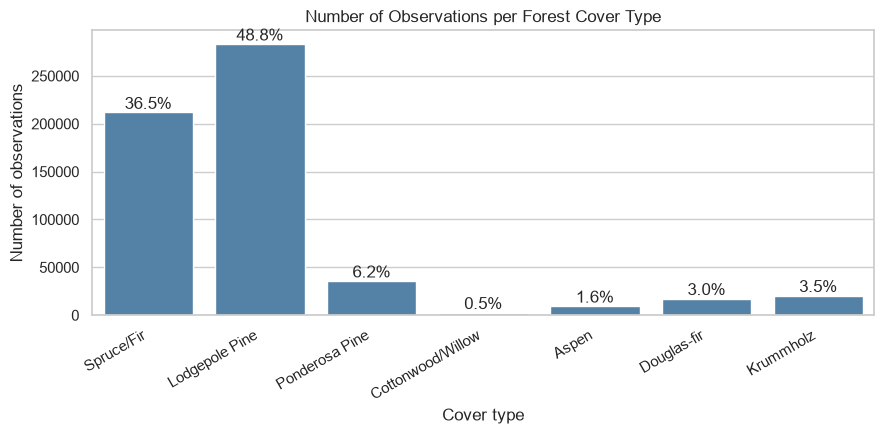

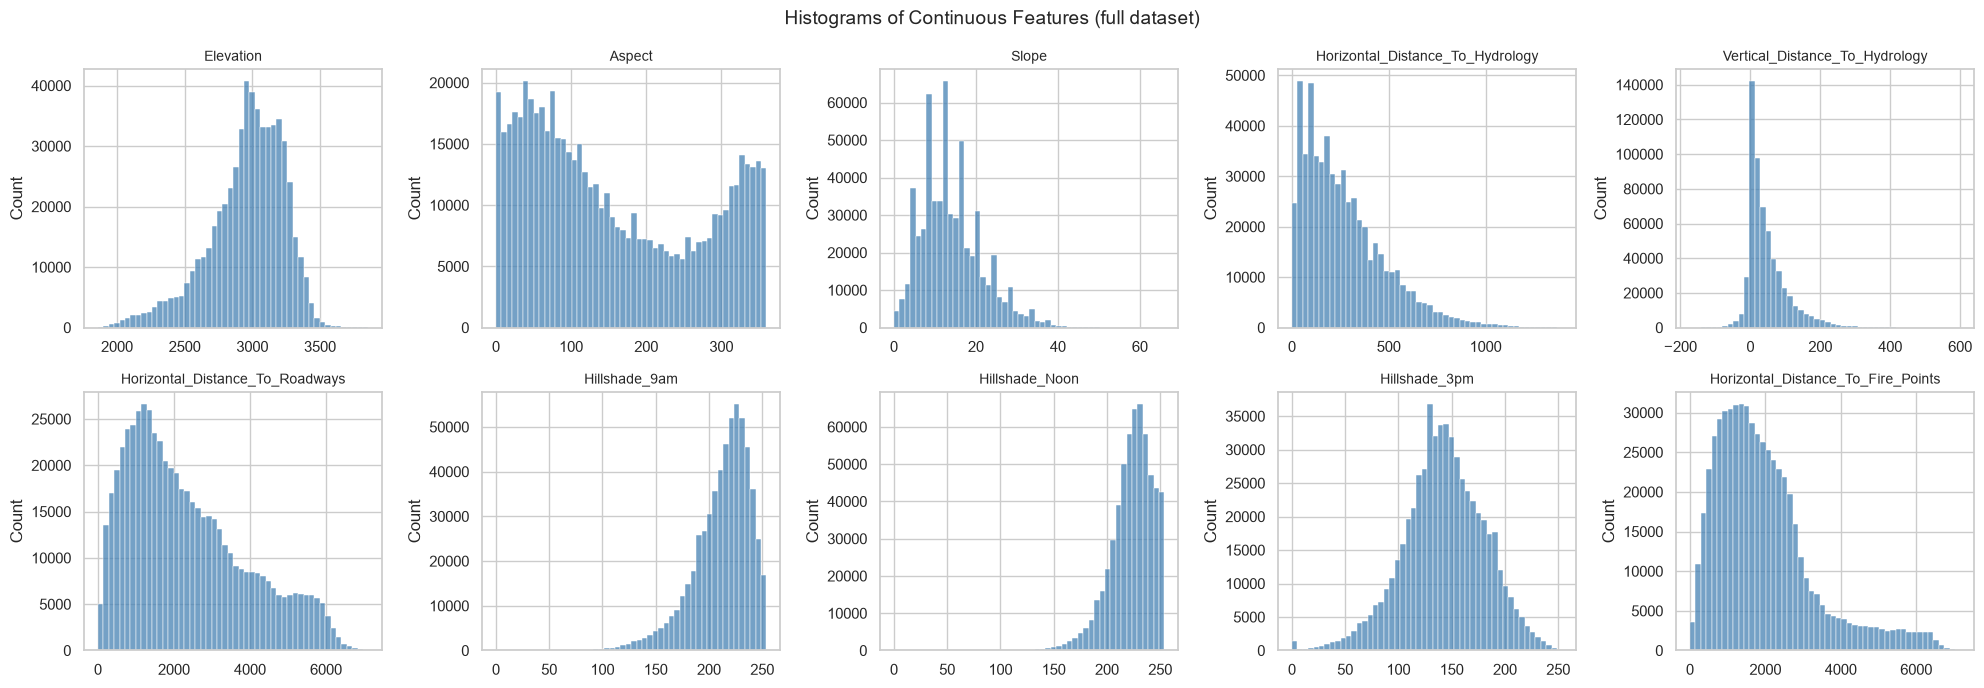

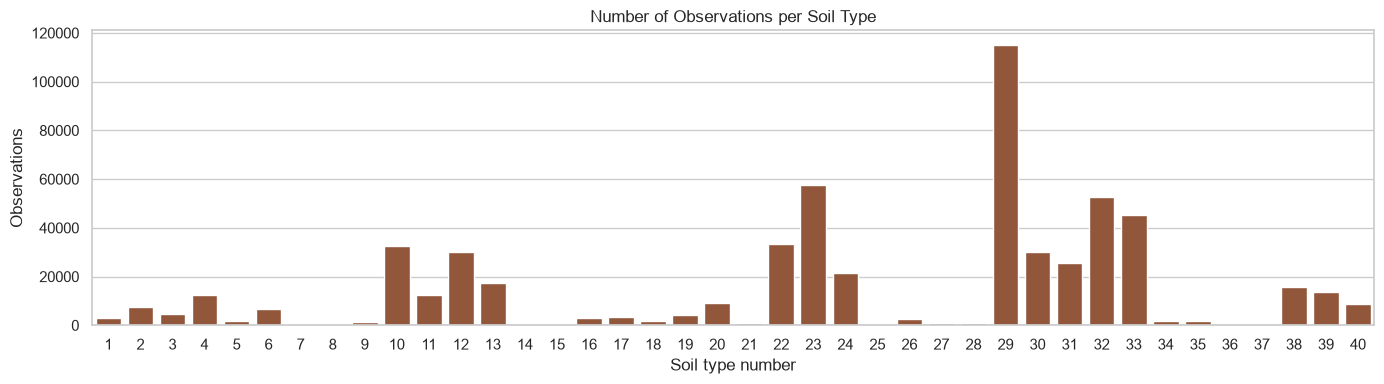

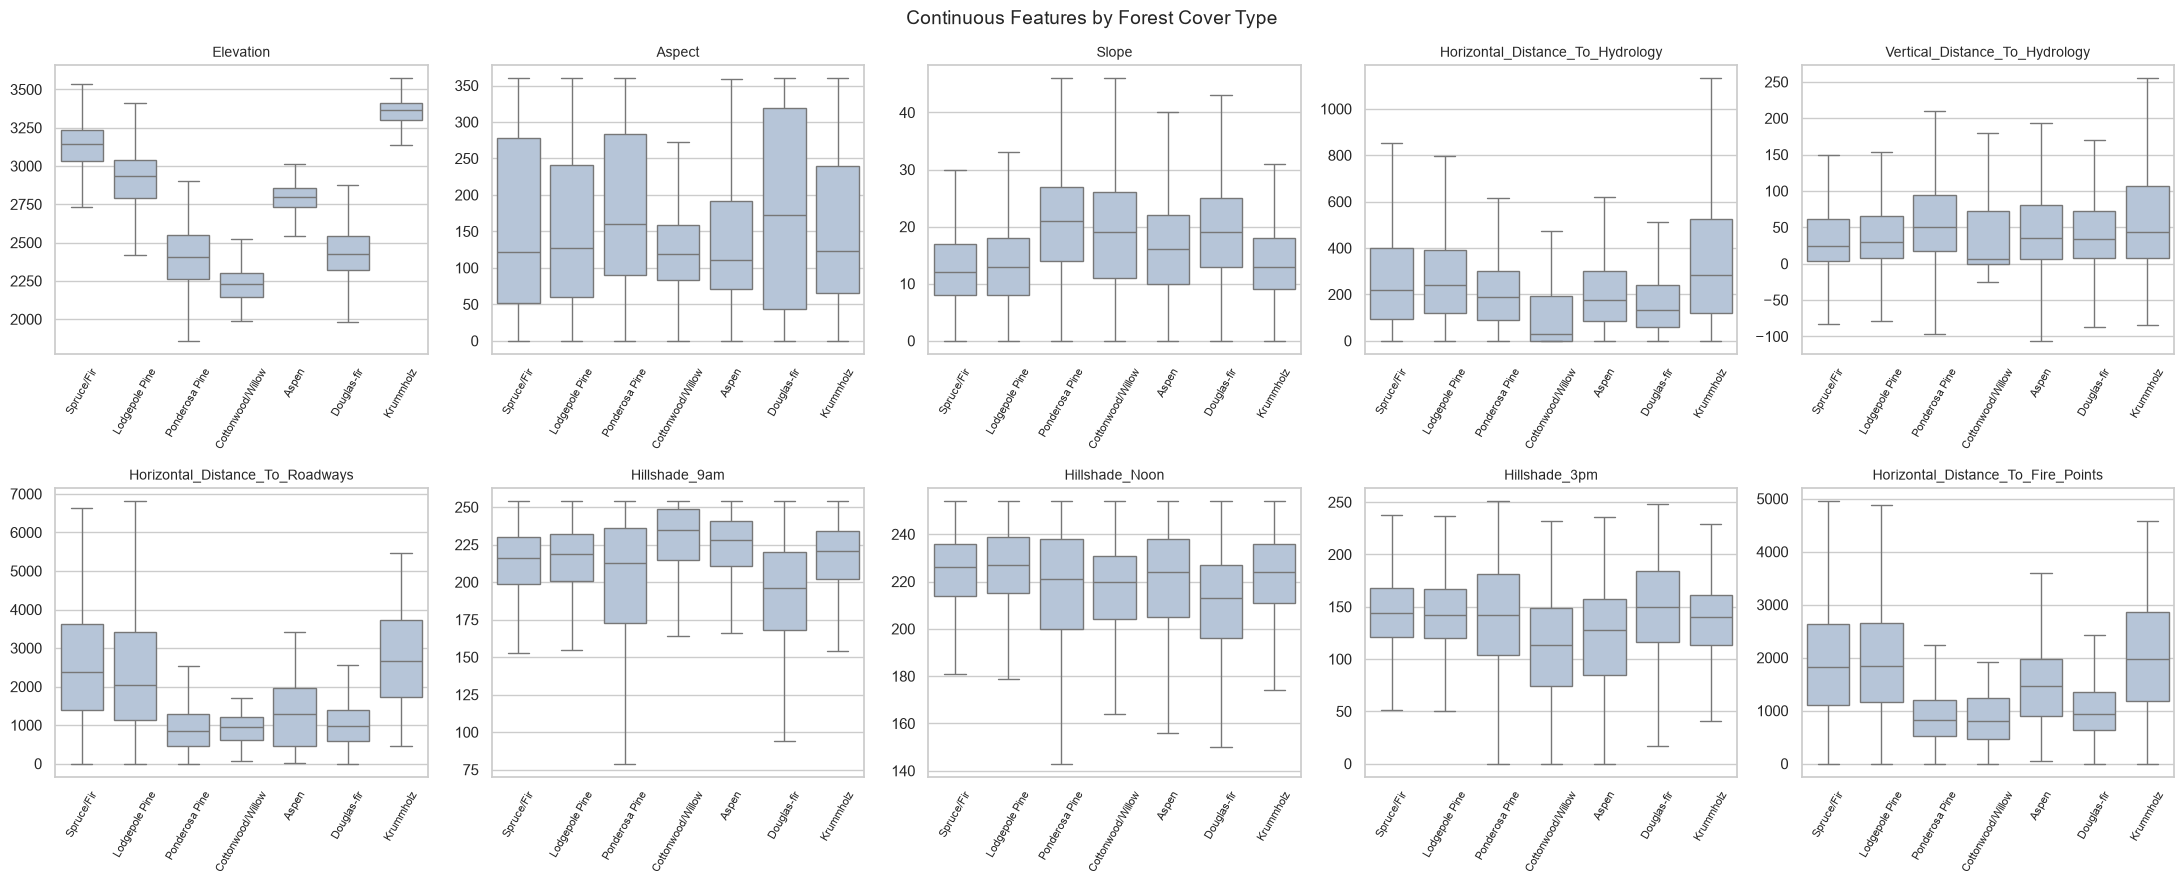

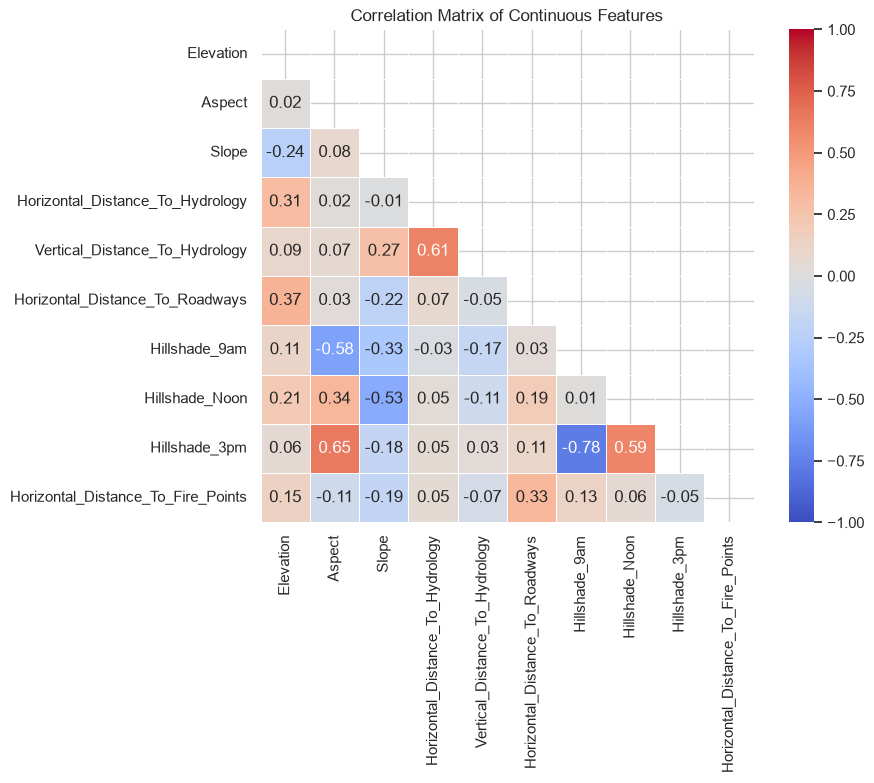

Correlation
Hillshade_3pm                  Hillshade_9am                          -0.780
                               Aspect                                  0.647
Vertical_Distance_To_Hydrology Horizontal_Distance_To_Hydrology        0.606
Hillshade_3pm                  Hillshade_Noon                          0.594
Hillshade_9am                  Aspect                                 -0.579
Hillshade_Noon                 Slope                                  -0.527

In [39]:
# Build a small DataFrame just for the EDA plots
# It wouldn't make sense to plot the one-hot columns directly (44 separate 0/1 columns),
# so this copy of the df uses the original columns and collapses them back into single labeled columns. 
# 
# This copy is only for EDA plotting purposes. The models will still use the one-hot columns

eda_df = df[continuous_cols].copy()

# argmax finds the position of the "1" in each row. Adding 1 converts the 0-based position into the 1-based area/soil number used in covtype.info
wilderness_num = df[wilderness_cols].to_numpy().argmax(axis=1) + 1
soil_num = df[soil_cols].to_numpy().argmax(axis=1) + 1

eda_df["Wilderness"] = pd.Series(wilderness_num, index=df.index).map(wilderness_names)
eda_df["Soil_Type"] = soil_num
eda_df["Cover"] = pd.Categorical(df[target_col].map(cover_type_names), categories=cover_type_order, ordered=True)

# display the first few rows of the EDA DataFrame so the format of each column is visible
# display(eda_df.head())

#---------

# Plot the number of observations in each cover type class to see if the dataset is balanced or imbalanced
class_counts = eda_df["Cover"].value_counts().reindex(cover_type_order)
class_pct = 100 * class_counts / class_counts.sum()
# Bar chart
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=class_counts.index, y=class_counts.values, color="steelblue", ax=ax)
# Label each bar with its percentage so the imbalance is easy to read
for i, pct in enumerate(class_pct):
    ax.text(i, class_counts.iloc[i], f"{pct:.1f}%", ha="center", va="bottom")

ax.set_title("Number of Observations per Forest Cover Type")
ax.set_xlabel("Cover type")
ax.set_ylabel("Number of observations")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

#---------

# Plot histograms of the 10 continuous features to see their distributions

fig, axes = plt.subplots(2, 5, figsize=(20, 7))

# axes is a 2x5 grid; flatten() turns it into a simple list of 10 plots
for ax, col in zip(axes.flatten(), continuous_cols):
    sns.histplot(eda_df[col], bins=50, ax=ax, color="steelblue")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")

fig.suptitle("Histograms of Continuous Features (full dataset)", fontsize=14)
plt.tight_layout()
plt.show()

# Skew puts a number on what the histograms show
# Generally, skew<.5 is fairly symmetric, skew>1 is strongly skewed
eda_df[continuous_cols].skew().round(2).to_frame("Skewness")

#---------

# Plot how common each soil type is overall (bar chart)
soil_freq = eda_df["Soil_Type"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(14, 4))
sns.barplot(x=soil_freq.index, y=soil_freq.values, color="sienna", ax=ax)
ax.set_title("Number of Observations per Soil Type")
ax.set_xlabel("Soil type number")
ax.set_ylabel("Observations")
plt.tight_layout()
plt.show()

#---------

# Display box plots for each continuous feature broken down by cover type
# Boxes at very different heights for different classes is often indicative of a useful feature for prediction

fig, axes = plt.subplots(2, 5, figsize=(22, 9))

for ax, col in zip(axes.flatten(), continuous_cols):
    # showfliers=False hides the individual outlier dots. There are too many of them and they make the boxes hard to read
    sns.boxplot(data=eda_df, x="Cover", y=col, ax=ax, showfliers=False, color="lightsteelblue")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=60, labelsize=8)

fig.suptitle("Continuous Features by Forest Cover Type", fontsize=14)
plt.tight_layout()
plt.show()

#---------

# A correlation matrix shows which features carry similar information
# Pearson correlation values near +1 or -1 mean two features move together closely, and values near 0 mean little linear relationship 
# Highly correlated features are not a problem for tree models, but they are worth noting for interpreting feature importance later

corr = eda_df[continuous_cols].corr()

# Only show the lower triangle, since the upper half is a mirror image
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation Matrix of Continuous Features")
plt.tight_layout()
plt.show()

# List the most strongly correlated pairs so they are easy to reference in the discussion
# stack() turns the matrix into a list of (feature A, feature B) pairs
pairs = corr.where(~mask).stack().rename("Correlation")
pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(6).round(3).to_frame()



#### Discussion of EDA plots

Some important observations can be made based on the EDA plots above. First, the target variable itself is unbalanced, with 2 of the 7 cover types accounting for ~85% of all observations. The unbalanced data may make it difficult for the models to correctly predict the 5 less common cover types. Stratified sampling will be critical to preserve the class proportions. 

When examining the 10 continuous features, many of the distance based features exhibit a noticeable skew. Elevation and Hillshade 3pm seem to have the most symmetric distributions. As previously discussed in the summary, the value ranges will need to be addressed when prepping the data for SVM. Soil types are also unevenly distributed, with observations concentrated among about a dozen soil types. 

The box plots of continuous features broken down by cover type are useful for predictive purposes. Boxes at very different heights for different classes is often indicative of a useful feature for prediction, while many overlapping boxes indicates the feature may be less useful. Based on this theory, I can predict that elevation will be found to be the strongest predictor of cover type. Other features show more overlap but may still be useful when considered together with additional environmental variables.

The correlation matrix shows which features carry similar information and are therefore highly correlated. Pearson correlation values near 1 or -1 mean two features move together closely, and values near 0 mean there is little linear relationship. Most features have relatively weak correlations, although there are stronger relationships among some of the hillshade variables and between horizontal and vertical distance to hydrology. Correlated features do not necessarily need to be removed for Decision Tree or Random Forest models, but they should be considered when interpreting feature importance because correlated variables may compete for importance within a model.

---



## IC: Project Design and Special Considerations

To ensure consistency of metrics across models, one evaluation function will be written and then run on every model. The metrics recorded will be as follows:
   - Train and test accuracy: the gap between them is a sign of overfitting
   - Macro precision, recall, and F1: "macro" means the score is computed for each class separately and then averaged, so every cover type counts equally no matter how rare it is. This matters because the classes are imbalanced, but it's still necessary to accurately evaluate the results for each class.
   - Fit and predict time: needed for the scalability comparison

Decision Trees and Random Forests split on one feature at a time, so the units of a feature do not matter to them. SVM is different, since it measures distances between points. In an SVM model, a feature measured in thousands (like distance to roadways) would overpower a feature measured from 0 to 1 (like a soil type indicator). Comparing the ranges shows how large this difference is across features.

In [43]:
# Define the evaluation function that will be used to fit each model and return a dictionary of performance metrics
def evaluate_model(model, X_train, y_train, X_test, y_test):
    """Fit a model, then return a dictionary of performance metrics."""

    # Time the training step
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_time = time.perf_counter() - start

    # Time the prediction step on the test set
    start = time.perf_counter()
    y_test_pred = model.predict(X_test)
    predict_time = time.perf_counter() - start

    # Predictions on the training data are only used to measure overfitting
    y_train_pred = model.predict(X_train)

    # zero_division=0 avoids a warning if a model never predicts some class
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, y_test_pred, average="macro", zero_division=0
    )

    return {
        "Train Accuracy": accuracy_score(y_train, y_train_pred),
        "Test Accuracy": accuracy_score(y_test, y_test_pred),
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Fit Time (s)": fit_time,
        "Predict Time (s)": predict_time,
    }

Section II: Preliminary Models and Hyperparameter Observations

This section will create a medium-sized stratified random sample on which each of the 3 models can be trained. Each model will be trained on a set of hyperparameters that should illustrate how the hyperparameters affect the model performance. This section's exploration of hyperparameters of each model will determine the starting values for final model parameters.

II A: Decision Tree (DT)


II B: Random Forest (RF)


II C: Support Vector Machine (SVM)

Section II Results Discussion

Section III: Repeated Model Evaluation on Stratified Random Samples

This section is where I will run 20 trials of each model. I will compare performance of each model across trials, as well as compare each model's average performance to each other's. 

Section III Results Discussion

Placeholder

Section IV: Scalability

A problem I have run into in the past is the scalability of anlaysis. I will run each model on samples of 1000, 10000, and 100000 and record the training time for each. This experiment will also determine if I can run each model on the full dataset.  

Section IV Results Discussion

Section V: Final Model Training and Comparison

Section V Results Discussion